You are given a personal information string s, representing either an email address or a phone number. Return the masked personal information using the below rules.

Email address:

An email address is:

A name consisting of at least two uppercase and lowercase English letters, followed by
The '@' symbol, followed by
The domain consisting of uppercase and lowercase English letters with a dot '.' somewhere in the middle (not the first or last character).
To mask an email:

The uppercase letters in the name and domain must be converted to lowercase letters.
The middle letters of the name (i.e., all but the first and last letters) must be replaced by 5 asterisks "*****".
Phone number:

A phone number is formatted as follows:

The phone number contains 10-13 digits.
The last 10 digits make up the local number.
The remaining 0-3 digits, in the beginning, make up the country code.
Separation characters from the set {'+', '-', '(', ')', ' '} separate the above digits in some way.
To mask a phone number:

Remove all separation characters.
The masked phone number should have the form:
"***-***-XXXX" if the country code has 0 digits.
"+*-***-***-XXXX" if the country code has 1 digit.
"+**-***-***-XXXX" if the country code has 2 digits.
"+***-***-***-XXXX" if the country code has 3 digits.
"XXXX" is the last 4 digits of the local number.


Example 1:

Input: s = "LeetCode@LeetCode.com"
Output: "l*****e@leetcode.com"
Explanation: s is an email address.
The name and domain are converted to lowercase, and the middle of the name is replaced by 5 asterisks.
Example 2:

Input: s = "AB@qq.com"
Output: "a*****b@qq.com"
Explanation: s is an email address.
The name and domain are converted to lowercase, and the middle of the name is replaced by 5 asterisks.
Note that even though "ab" is 2 characters, it still must have 5 asterisks in the middle.
Example 3:

Input: s = "1(234)567-890"
Output: "***-***-7890"
Explanation: s is a phone number.
There are 10 digits, so the local number is 10 digits and the country code is 0 digits.
Thus, the resulting masked number is "***-***-7890".


Constraints:

s is either a valid email or a phone number.
If s is an email:
8 <= s.length <= 40
s consists of uppercase and lowercase English letters and exactly one '@' symbol and '.' symbol.
If s is a phone number:
10 <= s.length <= 20
s consists of digits, spaces, and the symbols '(', ')', '-', and '+'.

In [ ]:
fun maskPII(s: String): String {
    val result = StringBuilder()

    if (s[0].isLetter()) {
        result.append(s[s.length-1].lowercaseChar())
        for (c in s.length-2 downTo 0) {
            result.append(s[c].lowercaseChar())
            if (s[c+1] == '@')
                break
        }
        result.append("*****${s[0].lowercaseChar()}")

    }
    else {
        var countryCode = s.count { it.isDigit() } % 10
        for (i in s.length - 1 downTo 0){
            if (result.length >= 4) break
            if (s[i].isDigit()){
                result.append(s[i])
            }
        }
        result.append("-***-***")

        if (countryCode > 0){
            result.append('-')

            for (i in 0..<s.length){
                if (countryCode <= 0) break
                if (s[i].isDigit()){
                    result.append('*')
                    countryCode--
                }
            }

            result.append('+')
        }
    }

    return result.reverse().toString()
}

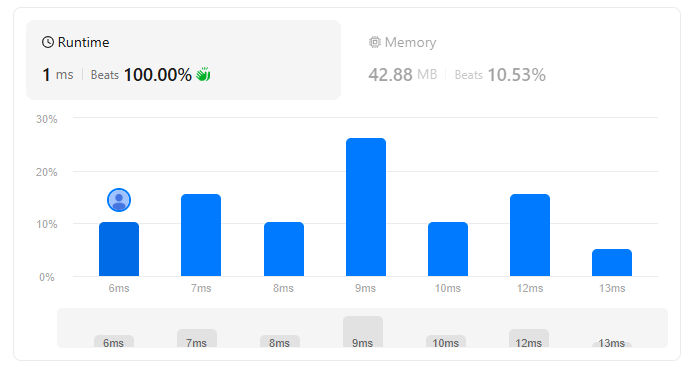